# Práctica integradora · Tema 5 (cubre Temas 1–5)
**GAB-2402 · Programación Avanzada**  
**Tecnológico de Estudios Superiores de Chalco**  
**Prof. Fabián Soberanes Martín**

---
Esta práctica une:
- **T1** Limpieza y manipulación (Pandas/NumPy)
- **T2** Visualización (Seaborn/Plotly)
- **T3** Estadística y modelado (scikit-learn)
- **T4** Persistencia en SQLite
- **T5** Preparación para app Streamlit

Dataset: `data/empleados_ventas.csv`

## 0. Configuración

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score, classification_report, accuracy_score

sns.set_theme(style='whitegrid')
BASE = Path('..') if Path('../data').exists() else Path('.')
DATA = BASE / 'empleados_ventas.csv'
DB = BASE / 'data' / 'analitica.db'
MODELS = BASE / 'models'
MODELS.mkdir(parents=True, exist_ok=True)
print('Dataset:', DATA.resolve())

Dataset: C:\Users\usuario\empleados_ventas.csv


---
## A. Tema 1 — Carga y limpieza

In [6]:
df_raw = pd.read_csv(DATA)
print(df_raw.shape)
print(df_raw.head())
print('\nNulos:\n', df_raw.isnull().sum())
print('Duplicados:', df_raw.duplicated().sum())

(503, 11)
   id  edad  experiencia_anios  educacion departamento ciudad genero  \
0   1  23.0                  0          2       Ventas    MTY      M   
1   2  27.0                  0          3  Operaciones    GDL      F   
2   3  49.0                 24          1    Marketing   CDMX      F   
3   4  50.0                 28          2     Finanzas    PUE      F   
4   5  47.0                 20          2           IT    MTY      F   

   horas_extra_mes  satisfaccion  antiguedad_empresa       salario  
0               13             5                   0  21996.657953  
1                8             1                   0  22400.526040  
2                3             2                  22  47956.992642  
3                3             2                  24  49006.078411  
4                7             5                  18  41829.902747  

Nulos:
 id                     0
edad                   6
experiencia_anios      0
educacion              0
departamento           0
ciudad   

In [7]:
# TODO A1: Pipeline de limpieza

df = df_raw.copy()

# 1. Eliminar registros duplicados
df = df.drop_duplicates()

# 2. Imputar edad con la mediana
df['edad'] = df['edad'].fillna(df['edad'].median())

# 3. Imputar salario con la mediana por departamento
df['salario'] = df.groupby('departamento')['salario'].transform(
    lambda x: x.fillna(x.median())
)

# 4. Tratar valores extremos del salario usando IQR
Q1 = df['salario'].quantile(0.25)
Q3 = df['salario'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Limitar salarios extremos
df['salario'] = df['salario'].clip(
    lower=limite_inferior,
    upper=limite_superior
)

# 5. Crear salario anual
df['salario_anual'] = df['salario'] * 12

# 6. Crear variable es_it
df['es_it'] = df['departamento'].str.contains(
    'IT|Informática|Sistemas',
    case=False,
    na=False,
    regex=True
).astype(int)

# 7. Crear rango de edad
df['rango_edad'] = pd.cut(
    df['edad'],
    bins=[0, 25, 35, 45, 60, float('inf')],
    labels=['18-25', '26-35', '36-45', '46-60', '60+']
)

# 8. Mostrar resultados
print("Dimensiones del DataFrame:", df.shape)

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDuplicados restantes:", df.duplicated().sum())

print("\nPrimeros registros:")
display(df.head())


Dimensiones del DataFrame: (500, 14)

Valores nulos:
id                    0
edad                  0
experiencia_anios     0
educacion             0
departamento          0
ciudad                0
genero                0
horas_extra_mes       0
satisfaccion          0
antiguedad_empresa    0
salario               0
salario_anual         0
es_it                 0
rango_edad            0
dtype: int64

Duplicados restantes: 0

Primeros registros:


,id,edad,experiencia_anios,educacion,departamento,ciudad,genero,horas_extra_mes,satisfaccion,antiguedad_empresa,salario,salario_anual,es_it,rango_edad
0,1,23.0,0,2,Ventas,MTY,M,13,5,0,21996.657953,263959.895440,0,18-25
1,2,27.0,0,3,Operaciones,GDL,F,8,1,0,22400.526040,268806.312477,0,26-35
2,3,49.0,24,1,Marketing,CDMX,F,3,2,22,47956.992642,575483.911707,0,46-60
3,4,50.0,28,2,Finanzas,PUE,F,3,2,24,49006.078411,588072.940927,0,46-60
4,5,47.0,20,2,IT,MTY,F,7,5,18,41829.902747,501958.832966,1,46-60


---
## B. Tema 2 — Visualización exploratoria

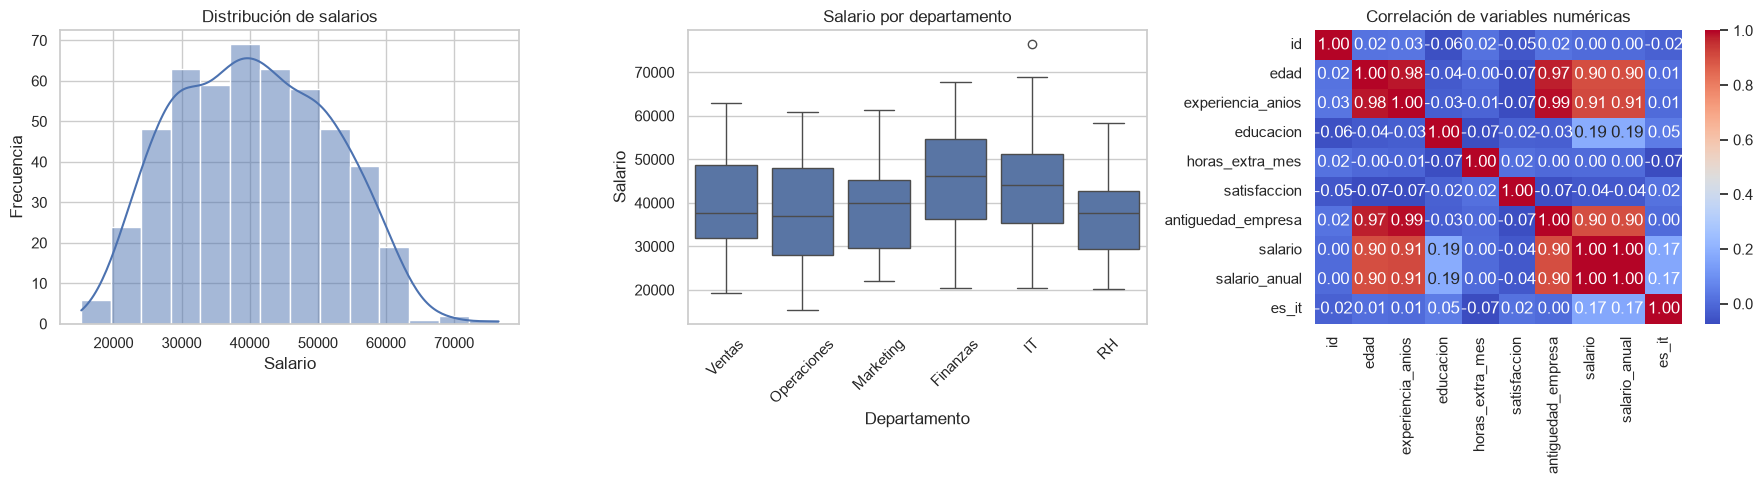

In [8]:

# TODO B1: Histograma/KDE de salario, boxplot por departamento y heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Crear las tres gráficas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma y curva KDE del salario
sns.histplot(
    data=df,
    x='salario',
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Distribución de salarios')
axes[0].set_xlabel('Salario')
axes[0].set_ylabel('Frecuencia')

# 2. Boxplot de salario por departamento
sns.boxplot(
    data=df,
    x='departamento',
    y='salario',
    ax=axes[1]
)
axes[1].set_title('Salario por departamento')
axes[1].set_xlabel('Departamento')
axes[1].set_ylabel('Salario')
axes[1].tick_params(axis='x', rotation=45)

# 3. Heatmap de correlación numérica
correlacion = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    ax=axes[2]
)
axes[2].set_title('Correlación de variables numéricas')

# Ajustar espacios
plt.tight_layout()
plt.show()


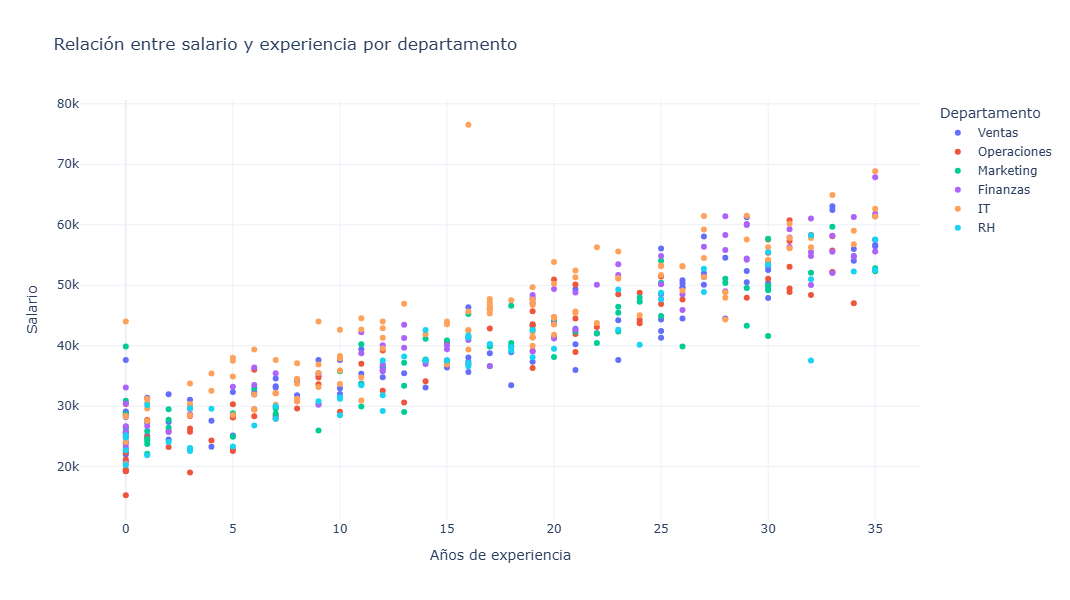

In [10]:

# TODO B2: Gráfico interactivo Plotly de salario vs experiencia


import plotly.express as px

fig = px.scatter(
    df,
    x='experiencia_anios',
    y='salario',
    color='departamento',
    title='Relación entre salario y experiencia por departamento',
    labels={
        'experiencia_anios': 'Años de experiencia',
        'salario': 'Salario',
        'departamento': 'Departamento'
    },
    hover_data=['edad', 'educacion', 'ciudad'],
    size_max=12
)

fig.update_layout(
    width=1000,
    height=600,
    template='plotly_white',
    legend_title='Departamento'
)

fig.show()



---
## C. Tema 3 — Estadística y modelado

In [11]:

# TODO C1: Comparar salario medio IT vs Ventas (t-test)

from scipy import stats

# Obtener salarios del departamento IT
salarios_it = df[df['departamento'].str.contains(
    'IT|Informática|Sistemas',
    case=False,
    na=False
)]['salario'].dropna()

# Obtener salarios del departamento Ventas
salarios_ventas = df[
    df['departamento'].str.contains(
        'Ventas',
        case=False,
        na=False
    )
]['salario'].dropna()

# Calcular promedios
media_it = salarios_it.mean()
media_ventas = salarios_ventas.mean()

# Aplicar prueba t-test independiente (Welch)
stat, p = stats.ttest_ind(
    salarios_it,
    salarios_ventas,
    equal_var=False
)

# Mostrar resultados
print("COMPARACIÓN DE SALARIOS: IT vs VENTAS")
print("--------------------------------------")
print(f"Empleados IT: {len(salarios_it)}")
print(f"Empleados Ventas: {len(salarios_ventas)}")
print(f"Salario promedio IT: ${media_it:.2f}")
print(f"Salario promedio Ventas: ${media_ventas:.2f}")
print(f"Estadístico t: {stat:.4f}")
print(f"Valor p: {p:.6f}")

# Interpretación del resultado
print("\nINTERPRETACIÓN:")

if p < 0.05:
    print("Existe una diferencia estadísticamente significativa entre los salarios medios de IT y Ventas.")
else:
    print("No existe evidencia suficiente de una diferencia estadísticamente significativa entre los salarios medios de IT y Ventas.")


COMPARACIÓN DE SALARIOS: IT vs VENTAS
--------------------------------------
Empleados IT: 116
Empleados Ventas: 96
Salario promedio IT: $43976.19
Salario promedio Ventas: $39470.71
Estadístico t: 3.0630
Valor p: 0.002491

INTERPRETACIÓN:
Existe una diferencia estadísticamente significativa entre los salarios medios de IT y Ventas.


In [12]:

# TODO C2: Regresión - Predecir salario

# Importar librerías
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Seleccionar características
features = [
    'edad',
    'experiencia_anios',
    'educacion',
    'horas_extra_mes',
    'satisfaccion',
    'antiguedad_empresa'
]

# 2. Preparar datos
X = df[features].copy()
y = df['salario'].copy()

# Convertir variables categóricas a numéricas si existen
X = pd.get_dummies(X, drop_first=True)

# Eliminar registros con valores nulos
datos = pd.concat([X, y.rename('salario')], axis=1)
datos = datos.dropna()

X = datos.drop(columns=['salario'])
y = datos['salario']

print("Registros disponibles:", len(X))

# 3. Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# 4. Escalar características
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Modelo de regresión lineal
modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train_scaled, y_train)

pred_lineal = modelo_lineal.predict(X_test_scaled)

# Evaluar modelo lineal
mae_lineal = mean_absolute_error(y_test, pred_lineal)
r2_lineal = r2_score(y_test, pred_lineal)

# 6. Modelo Random Forest
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)

# Evaluar Random Forest
mae_rf = mean_absolute_error(y_test, pred_rf)
r2_rf = r2_score(y_test, pred_rf)

# 7. Mostrar resultados
print("\n===== RESULTADOS DE LOS MODELOS =====")

print("\nREGRESIÓN LINEAL")
print("MAE:", round(mae_lineal, 2))
print("R2:", round(r2_lineal, 4))

print("\nRANDOM FOREST")
print("MAE:", round(mae_rf, 2))
print("R2:", round(r2_rf, 4))

# 8. Comparación de modelos
resultados = pd.DataFrame({
    'Modelo': ['Regresión Lineal', 'Random Forest'],
    'MAE': [mae_lineal, mae_rf],
    'R2': [r2_lineal, r2_rf]
})

print("\n===== COMPARACIÓN =====")
display(resultados)

# 9. Identificar el mejor modelo
mejor_modelo = (
    'Regresión Lineal'
    if mae_lineal < mae_rf
    else 'Random Forest'
)

print("\nMejor modelo según MAE:", mejor_modelo)


Registros disponibles: 500

===== RESULTADOS DE LOS MODELOS =====

REGRESIÓN LINEAL
MAE: 2960.84
R2: 0.8512

RANDOM FOREST
MAE: 3318.18
R2: 0.8292

===== COMPARACIÓN =====


,Modelo,MAE,R2
0,Regresión Lineal,2960.844152,0.851156
1,Random Forest,3318.175488,0.829228



Mejor modelo según MAE: Regresión Lineal


In [13]:

# TODO C3: Clasificación - salario_alto

# Importar librerías
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Crear variable objetivo
mediana_salario = df['salario'].median()

df['salario_alto'] = (
    df['salario'] > mediana_salario
).astype(int)

# 2. Seleccionar características
features = [
    'edad',
    'experiencia_anios',
    'educacion',
    'horas_extra_mes',
    'satisfaccion',
    'antiguedad_empresa'
]

X = df[features].copy()
y = df['salario_alto'].copy()

# Convertir variables categóricas a numéricas
X = pd.get_dummies(X, drop_first=True)

# Eliminar registros nulos
datos = pd.concat([X, y.rename('salario_alto')], axis=1)
datos = datos.dropna()

X = datos.drop(columns=['salario_alto'])
y = datos['salario_alto']

# 3. Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Escalar características
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Entrenar Logistic Regression
modelo_logistico = LogisticRegression(max_iter=1000)

modelo_logistico.fit(X_train_scaled, y_train)

pred_logistico = modelo_logistico.predict(X_test_scaled)

# 6. Entrenar Random Forest Classifier
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)

# 7. Mostrar resultados Logistic Regression
print("===== LOGISTIC REGRESSION =====")
print("Exactitud:", round(accuracy_score(y_test, pred_logistico), 4))

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    pred_logistico,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_logistico))

# 8. Mostrar resultados Random Forest
print("\n===== RANDOM FOREST CLASSIFIER =====")
print("Exactitud:", round(accuracy_score(y_test, pred_rf), 4))

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    pred_rf,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_rf))


===== LOGISTIC REGRESSION =====
Exactitud: 0.89

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.91      0.86      0.89        50
           1       0.87      0.92      0.89        50

    accuracy                           0.89       100
   macro avg       0.89      0.89      0.89       100
weighted avg       0.89      0.89      0.89       100

Matriz de confusión:
[[43  7]
 [ 4 46]]

===== RANDOM FOREST CLASSIFIER =====
Exactitud: 0.88

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88        50
           1       0.87      0.90      0.88        50

    accuracy                           0.88       100
   macro avg       0.88      0.88      0.88       100
weighted avg       0.88      0.88      0.88       100

Matriz de confusión:
[[43  7]
 [ 5 45]]


In [14]:

# TODO C4: Guardar el mejor modelo de regresión

import joblib
from pathlib import Path

# 1. Crear carpeta para guardar los modelos
MODELS = Path("models")
MODELS.mkdir(parents=True, exist_ok=True)

# 2. Seleccionar el mejor modelo según MAE
if mae_lineal <= mae_rf:
    mejor_modelo = modelo_lineal
    nombre_modelo = "Regresión Lineal"
else:
    mejor_modelo = modelo_rf
    nombre_modelo = "Random Forest"

# 3. Guardar el mejor modelo
joblib.dump(
    mejor_modelo,
    MODELS / 'modelo_salario.joblib'
)

# 4. Guardar el scaler utilizado
joblib.dump(
    scaler,
    MODELS / 'scaler.joblib'
)

# 5. Guardar las características utilizadas
joblib.dump(
    list(X_train.columns),
    MODELS / 'features.joblib'
)

# 6. Mostrar resultados
print("Modelo seleccionado:", nombre_modelo)
print("MAE:", min(mae_lineal, mae_rf))
print("\nModelos guardados en:", MODELS.resolve())
print("\nArchivos guardados:")

for archivo in MODELS.iterdir():
    print("-", archivo.name)


Modelo seleccionado: Regresión Lineal
MAE: 2960.8441519409666

Modelos guardados en: C:\Users\usuario\models

Archivos guardados:
- features.joblib
- modelo_salario.joblib
- scaler.joblib


---
## D. Tema 4 — SQLite

In [15]:

# TODO D1: Guardar df limpio en SQLite y ejecutar consulta agregada

# 1. Importar librerías
import sqlite3
import pandas as pd
from pathlib import Path

# 2. Definir la ubicación de la base de datos
DB = Path("empleados.db")

# 3. Crear conexión con SQLite
conn = sqlite3.connect(DB)

# 4. Guardar DataFrame limpio en una tabla llamada empleados
df.to_sql(
    'empleados',
    conn,
    if_exists='replace',
    index=False
)

# 5. Crear consulta SQL
q = '''
SELECT
    departamento,
    COUNT(*) AS n,
    ROUND(AVG(salario), 2) AS salario_promedio
FROM empleados
GROUP BY departamento
ORDER BY salario_promedio DESC
'''

# 6. Ejecutar consulta y mostrar resultados
resultado = pd.read_sql(q, conn)

print("===== EMPLEADOS POR DEPARTAMENTO =====")
display(resultado)

# 7. Mostrar ubicación de la base de datos
conn.close()

print("\nBase de datos guardada en:", DB.resolve())


===== EMPLEADOS POR DEPARTAMENTO =====


,departamento,n,salario_promedio
0,Finanzas,75,44807.91
1,IT,116,43976.19
2,Ventas,96,39470.71
3,Marketing,76,38606.03
4,Operaciones,85,37489.86
5,RH,52,37243.10



Base de datos guardada en: C:\Users\usuario\empleados.db


In [16]:
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

df.to_csv(
    DATA_DIR / "empleados_limpios.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSV guardado correctamente")


CSV guardado correctamente


In [17]:
pip install streamlit pandas numpy matplotlib seaborn plotly scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [19]:
!streamlit --version

Streamlit, version 1.58.0


In [21]:
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

df.to_csv(
    DATA_DIR / "empleados_limpios.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente")

Archivo exportado correctamente


In [22]:
import os

print("Modelos guardados:")

for archivo in os.listdir("models"):
    print(archivo)

Modelos guardados:
features.joblib
modelo_salario.joblib
scaler.joblib


In [ ]:
!streamlit run app.py

In [ ]:
import os

print("Archivos de models:")
print(os.listdir("models"))

print("\nArchivos de data:")
print(os.listdir("data"))

In [1]:
from pathlib import Path

archivo = Path("app.py")

print("¿Existe el archivo?", archivo.exists())
print("Tamaño:", archivo.stat().st_size, "bytes")

print("\nContenido del archivo:")
print(archivo.read_text(encoding="utf-8")[:1500])

¿Existe el archivo? True
Tamaño: 5927 bytes

Contenido del archivo:
"""
App Streamlit — Proyecto integrador Tema 5 (GAB-2402)
Prof. Fabián Soberanes Martín

Ejecutar desde la raíz del tema:
    streamlit run app/app.py
"""

from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

# ---------------------------------------------------------------------------
# Rutas
# ---------------------------------------------------------------------------
BASE = Path(__file__).resolve().parent.parent
DATA_PATH = BASE / "data" / "empleados_ventas.csv"
MODEL_PATH = BASE / "models" / "modelo_salario.joblib"
SCALER_PATH = BASE / "models" / "scaler.joblib"

st.set_page_config(
    page_title="Analítica de Empleados · GAB-2402",
    page_icon="📊",
    layout="wide",
)


@st.cache_data
def load_data(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    # Limpieza mínima para que la demo funcione aunque el notebook no se haya corrido
    df = 

---
## E. Tema 5 — Checklist para la app

Antes de abrir Streamlit, verifica:
1. CSV limpio exportado o BD lista
2. Modelo `.joblib` guardado
3. `app/app.py` apunta a las rutas correctas

```bash
streamlit run app/app.py
```

### Entrega del proyecto
- Notebook ejecutado de punta a punta
- App con: filtros, ≥2 gráficos, métricas KPI, predicción de salario
- README con problema, método, resultados y limitaciones

**¡Éxito en el proyecto integrador!**  
*Prof. Fabián Soberanes Martín*